# SYDE 572 — Assignment 3

This notebook uses the Iris data loaded in the first code cell from the course's UCI repository dataset. It includes the handwritten work for Part 1 and the code, plots, and analysis for Parts 2–5.

## Part 1 — Handwritten work

![Handwritten Part 1, page 1](IMG_1537.JPG)

![Handwritten Part 1, page 2](IMG_1538.JPG)

![Handwritten Part 1, page 3](IMG_1539.JPG)

## Part 2 — Data visualization by marginalization


In [13]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
iris = fetch_ucirepo(id=53) 
  
# data (as pandas dataframes) 
X = iris.data.features 
y = iris.data.targets 
  
# metadata 
print(iris.metadata) 
  
# variable information 
print(iris.variables)

{'uci_id': 53, 'name': 'Iris', 'repository_url': 'https://archive.ics.uci.edu/dataset/53/iris', 'data_url': 'https://archive.ics.uci.edu/static/public/53/data.csv', 'abstract': 'A small classic dataset from Fisher, 1936. One of the earliest known datasets used for evaluating classification methods.\n', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 150, 'num_features': 4, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1936, 'last_updated': 'Tue Sep 12 2023', 'dataset_doi': '10.24432/C56C76', 'creators': ['R. A. Fisher'], 'intro_paper': {'ID': 191, 'type': 'NATIVE', 'title': 'The Iris data set: In search of the source of virginica', 'authors': 'A. Unwin, K. Kleinman', 'venue': 'Significance, 2021', 'year': 2021, 'journal': 'Significance, 2021', 'DOI': '1740-9713.01589', 'URL': 'https://www.semanticscholar.org

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from pathlib import Path

# Save generated figures beside this notebook in a plots folder.
working_dir = Path.cwd()
notebook_dir = working_dir / "Assignment 3" if (working_dir / "Assignment 3").is_dir() else working_dir
plot_dir = notebook_dir / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)

# Use the X and y DataFrames created in code cell 1 (UCI Iris data).
# Keep the feature names before converting X to a numeric NumPy array.
feature_names = X.columns.tolist()
X = X.to_numpy(dtype=float)

# The UCI target is a one-column DataFrame of class names. Convert its
# categories to integer labels while retaining readable names for plots.
y_values = y.squeeze().astype(str)
target_names = np.sort(y_values.unique())
y = pd.Categorical(y_values, categories=target_names).codes

print(f"X shape: {X.shape}")
print("Features:", feature_names)
print("Classes:", list(target_names))
print("Class counts:", pd.Series(y_values).value_counts().to_dict())

X shape: (150, 4)
Features: ['sepal length', 'sepal width', 'petal length', 'petal width']
Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Class counts: {'Iris-setosa': 50, 'Iris-versicolor': 50, 'Iris-virginica': 50}


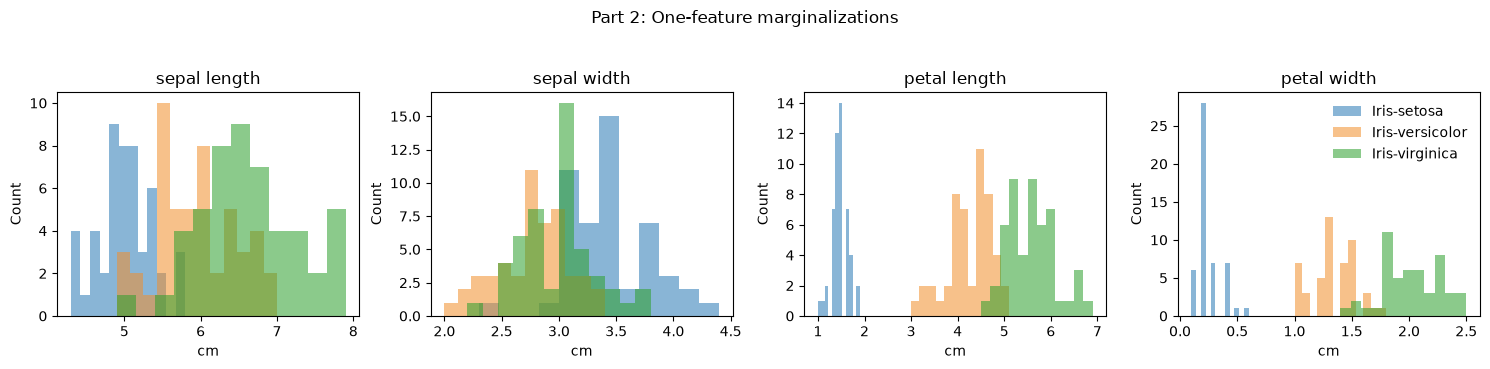

In [15]:
colors = ["#2878B5", "#F28E2B", "#2CA02C"]

# One feature: overlaid class distributions
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for j, ax in enumerate(axes):
    for k, name in enumerate(target_names):
        ax.hist(X[y == k, j], bins=12, alpha=0.55, color=colors[k], label=name)
    ax.set(title=feature_names[j], xlabel="cm", ylabel="Count")
axes[-1].legend(frameon=False)
fig.suptitle("Part 2: One-feature marginalizations", y=1.04)
fig.tight_layout()
fig.savefig(plot_dir / "part2_one_feature_marginalizations.jpg", dpi=300, bbox_inches="tight")
plt.show()

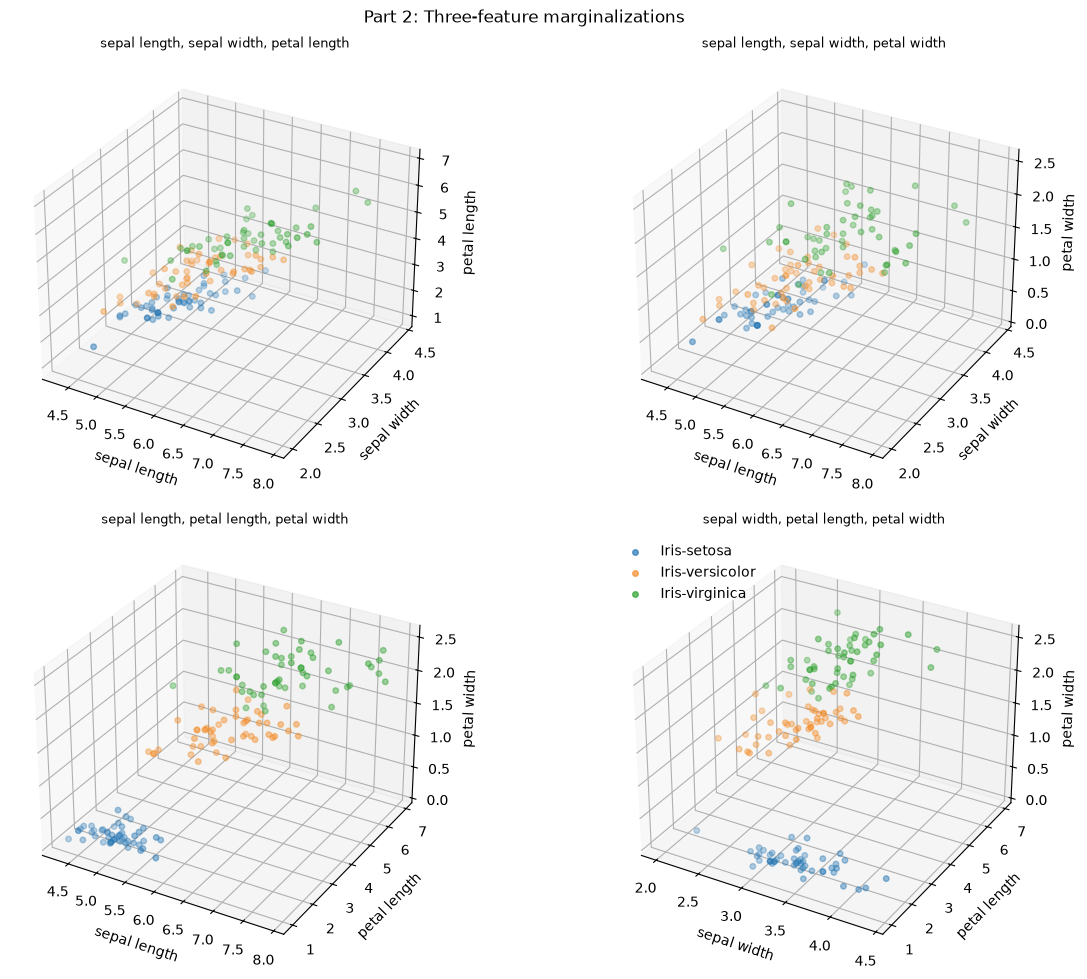

In [15]:
# Three-feature views: show all four feature triples as 3D scatter plots
fig = plt.figure(figsize=(13, 10))
triples = list(combinations(range(4), 3))
for plot_i, triple in enumerate(triples, start=1):
    ax = fig.add_subplot(2, 2, plot_i, projection="3d")
    for k, name in enumerate(target_names):
        mask = y == k
        ax.scatter(X[mask, triple[0]], X[mask, triple[1]], X[mask, triple[2]],
                   s=16, alpha=0.7, color=colors[k], label=name)
    ax.set_xlabel(feature_names[triple[0]], labelpad=5)
    ax.set_ylabel(feature_names[triple[1]], labelpad=5)
    ax.set_zlabel(feature_names[triple[2]], labelpad=3)
    ax.set_title(", ".join(feature_names[i] for i in triple), fontsize=9)
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 1.0), frameon=False)
fig.suptitle("Part 2: Three-feature marginalizations", y=0.98)
fig.tight_layout()
fig.savefig(plot_dir / "part2_three_feature_marginalizations.jpg", dpi=300, bbox_inches="tight")
plt.show()

### Part 2 observations
In 2D space, all the combinations create clear clustering except for sepal length vs. petal width. In 3D space, we see the clearest clustering when comparing sepal length with petal length and width, and sepal width with petal length and width. Otherwise, the clustering is not as obvious.
The separation for setosa is always clearest, while the boundaries for versicolor and virginica are much closer and harder to clearly identify which cluster the point belongs to.

## Part 3 — PCA

In [17]:
from sklearn.decomposition import PCA

pca = PCA(n_components=4)
Z = pca.fit_transform(X)
components = pca.components_

component_table = pd.DataFrame(
    components,
    index=[f"PC{i+1}" for i in range(4)],
    columns=feature_names,
)
print("PCA axis vectors (rows are PCs; columns follow the feature order above):")
display(component_table)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Cumulative explained variance:", np.cumsum(pca.explained_variance_ratio_))

PCA axis vectors (rows are PCs; columns follow the feature order above):


,sepal length,sepal width,petal length,petal width
PC1,0.361590,-0.082269,0.856572,0.358844
PC2,0.656540,0.729712,-0.175767,-0.074706
PC3,-0.580997,0.596418,0.072524,0.549061
PC4,0.317255,-0.324094,-0.479719,0.751121


Explained variance ratio: [0.92461621 0.05301557 0.01718514 0.00518309]
Cumulative explained variance: [0.92461621 0.97763178 0.99481691 1.        ]


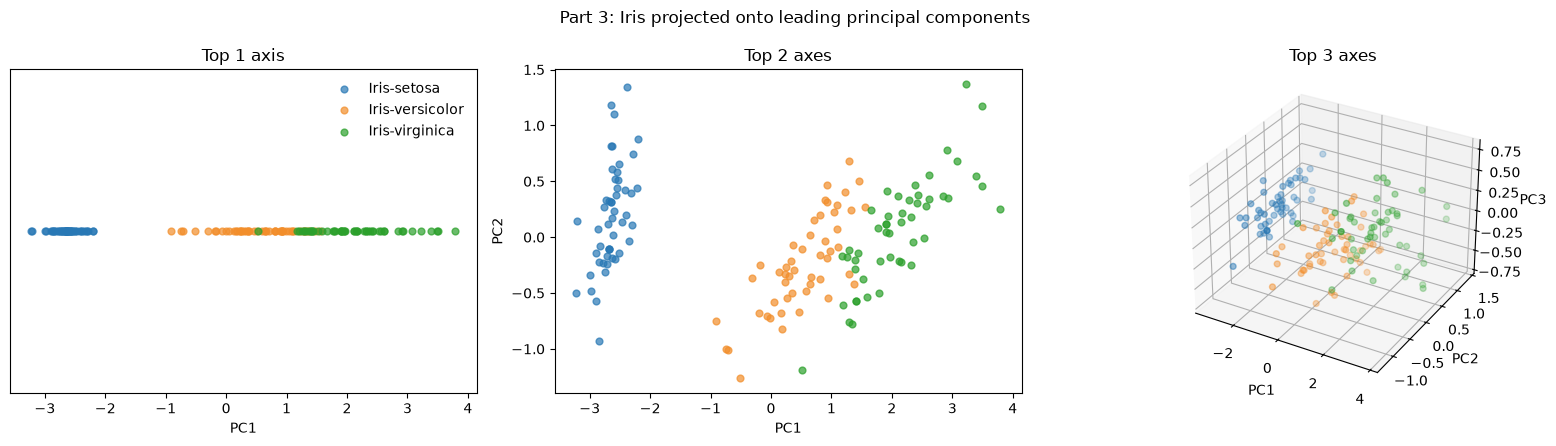

In [17]:
# Marginalize onto PC1, the top two PCs, and the top three PCs
fig = plt.figure(figsize=(16, 4.5))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3, projection="3d")
for k, name in enumerate(target_names):
    mask = y == k
    ax1.scatter(Z[mask, 0], np.zeros(mask.sum()), s=24, alpha=0.7, color=colors[k], label=name)
    ax2.scatter(Z[mask, 0], Z[mask, 1], s=24, alpha=0.7, color=colors[k], label=name)
    ax3.scatter(Z[mask, 0], Z[mask, 1], Z[mask, 2], s=18, alpha=0.7, color=colors[k], label=name)
ax1.set(xlabel="PC1", yticks=[], title="Top 1 axis")
ax2.set(xlabel="PC1", ylabel="PC2", title="Top 2 axes")
ax3.set_xlabel("PC1"); ax3.set_ylabel("PC2"); ax3.set_zlabel("PC3"); ax3.set_title("Top 3 axes")
ax1.legend(frameon=False)
fig.suptitle("Part 3: Iris projected onto leading principal components")
fig.tight_layout()
fig.savefig(plot_dir / "part3_pca_projections.jpg", dpi=300, bbox_inches="tight")
plt.show()

### Part 3 observations

Just one PC is quite good at dividing up the data, so we can clearly identify the majority of cases, with some issues arising at the versicolor/virginica boundary. This is further improved by using 2 PCs, where we can clearly see clustering with minimal boundary overlap. 3 PCs arguably look slightly noisy.

## Part 4 — Data compression

The assignment's variance fraction for a retained PCA representation is the sum of its explained-variance ratios. The following computes the fraction for two dimensions and the smallest number of leading PCs needed to reach 50%.

In [20]:
variance_ratio = pca.explained_variance_ratio_
two_pc_fraction = variance_ratio[:2].sum()
pcs_for_50 = int(np.searchsorted(np.cumsum(variance_ratio), 0.50) + 1)

print(f"Variance explained by 2D PCA representation: {two_pc_fraction:.4%}")
print(f"PCs required to explain at least 50% of variance: {pcs_for_50}")
print("Cumulative variance by number of PCs:", np.cumsum(variance_ratio))

Variance explained by 2D PCA representation: 97.7632%
PCs required to explain at least 50% of variance: 1
Cumulative variance by number of PCs: [0.92461621 0.97763178 0.99481691 1.        ]


### Part 4 answer

97.77% of the variance is explained by the first 2 PCs in our Iris dataset. One PC explains 92.46% of the variance, meaning we need just 1 PC to be able to explain at least 50% of the variance within the dataset.

## Part 5 — Nonlinear components with Isomap

Use the assignment's specified 3-nearest-neighbor graph. Isomap estimates graph geodesic distances and embeds them in two dimensions here for visualization. The three-dimensional result is also included for comparison with the PCA plot.

/opt/miniconda3/envs/iris/lib/python3.12/site-packages/sklearn/manifold/_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/opt/miniconda3/envs/iris/lib/python3.12/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


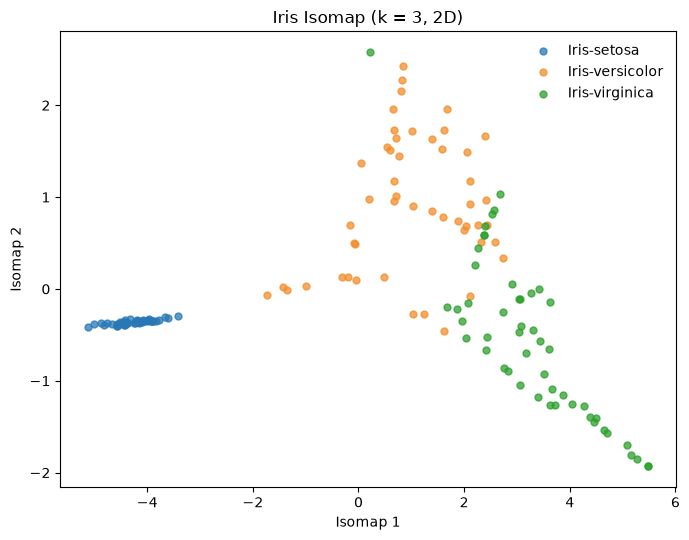

In [21]:
from sklearn.manifold import Isomap

isomap_2d = Isomap(n_neighbors=3, n_components=2)
Z_iso_2d = isomap_2d.fit_transform(X)

fig, ax = plt.subplots(figsize=(7, 5.5))
for k, name in enumerate(target_names):
    mask = y == k
    ax.scatter(Z_iso_2d[mask, 0], Z_iso_2d[mask, 1], s=25, alpha=0.75, color=colors[k], label=name)
ax.set(xlabel="Isomap 1", ylabel="Isomap 2", title="Iris Isomap (k = 3, 2D)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(plot_dir / "part5_isomap_2d.jpg", dpi=300, bbox_inches="tight")
plt.show()

/opt/miniconda3/envs/iris/lib/python3.12/site-packages/sklearn/manifold/_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/opt/miniconda3/envs/iris/lib/python3.12/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


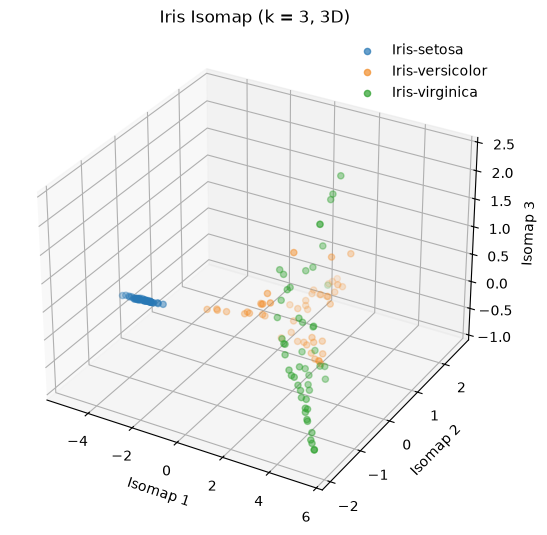

In [ ]:
isomap_3d = Isomap(n_neighbors=3, n_components=3)
Z_iso_3d = isomap_3d.fit_transform(X)

fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(111, projection="3d")
for k, name in enumerate(target_names):
    mask = y == k
    ax.scatter(Z_iso_3d[mask, 0], Z_iso_3d[mask, 1], Z_iso_3d[mask, 2],
               s=20, alpha=0.7, color=colors[k], label=name)
ax.set(xlabel="Isomap 1", ylabel="Isomap 2", zlabel="Isomap 3", title="Iris Isomap (k = 3, 3D)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(plot_dir / "part5_isomap_3d.jpg", dpi=300, bbox_inches="tight")
plt.show()

### Train/test classification comparison (10 repeated splits)

Compare how well the two-dimensional representations classify the three Iris targets. Repeat the stratified 2/3 train, 1/3 test split for `random_state` values 1 through 10. For each split, fit PCA or Isomap using only training features, then fit the same logistic-regression classifier on that representation. Report the mean accuracy and precision/recall/F1 across the ten held-out test sets, and display the mean confusion matrix.


PCA (2D) — averages over random_state=1..10
Mean accuracy: 0.940 (SD 0.030)
Mean macro precision: 0.941 (SD 0.030)
Mean macro recall: 0.940 (SD 0.030)
Mean macro f1: 0.940 (SD 0.030)
Mean precision by class:
  Iris-setosa: 1.000
  Iris-versicolor: 0.919
  Iris-virginica: 0.905

Isomap (2D, k=3) — averages over random_state=1..10
Mean accuracy: 0.936 (SD 0.030)
Mean macro precision: 0.939 (SD 0.030)
Mean macro recall: 0.936 (SD 0.030)
Mean macro f1: 0.936 (SD 0.030)
Mean precision by class:
  Iris-setosa: 1.000
  Iris-versicolor: 0.917
  Iris-virginica: 0.901


/opt/miniconda3/envs/iris/lib/python3.12/site-packages/sklearn/manifold/_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/opt/miniconda3/envs/iris/lib/python3.12/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
/opt/miniconda3/envs/iris/lib/python3.12/site-packages/sklearn/manifold/_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/opt/miniconda3/envs/iris/lib/python3.12/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is ex

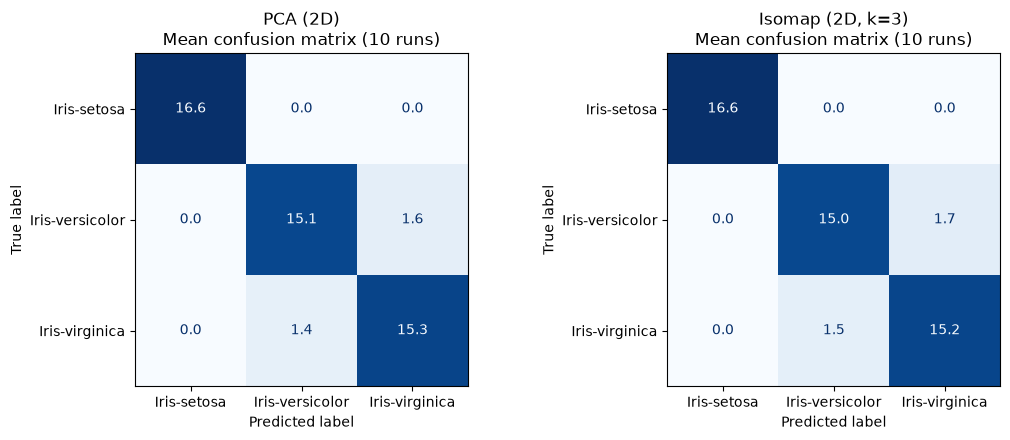

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

models = {
    "PCA (2D)": lambda: make_pipeline(
        PCA(n_components=2),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Isomap (2D, k=3)": lambda: make_pipeline(
        Isomap(n_neighbors=3, n_components=2),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
}

# Repeat a stratified 2/3 train, 1/3 test split for seeds 1 through 10.
results = {}
for name, make_model in models.items():
    run_metrics = []
    run_confusion_matrices = []

    for seed in range(1, 11):
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=1/3, random_state=seed, stratify=y
        )
        model = make_model()
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        run_metrics.append({
            "accuracy": accuracy_score(y_test, y_pred),
            "macro_precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
            "macro_recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
            "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
            "per_class_precision": precision_score(
                y_test, y_pred, average=None, labels=np.arange(len(target_names)), zero_division=0
            ),
        })
        run_confusion_matrices.append(
            confusion_matrix(y_test, y_pred, labels=np.arange(len(target_names)))
        )

    # Average the ten runs. Since each stratified split has the same class counts,
    # the averaged confusion matrix is an average number of predictions per split.
    results[name] = {
        "metrics": run_metrics,
        "average_confusion_matrix": np.mean(run_confusion_matrices, axis=0),
    }

    print(f"\n{name} — averages over random_state=1..10")
    for metric in ["accuracy", "macro_precision", "macro_recall", "macro_f1"]:
        values = [run[metric] for run in run_metrics]
        print(f"Mean {metric.replace('_', ' ')}: {np.mean(values):.3f} (SD {np.std(values, ddof=1):.3f})")
    mean_per_class_precision = np.mean(
        [run["per_class_precision"] for run in run_metrics], axis=0
    )
    print("Mean precision by class:")
    for class_name, score in zip(target_names, mean_per_class_precision):
        print(f"  {class_name}: {score:.3f}")

# Plot each model's mean confusion matrix over the ten test splits.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, result) in zip(axes, results.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=result["average_confusion_matrix"],
        display_labels=target_names,
    ).plot(cmap="Blues", colorbar=False, ax=ax, values_format=".1f")
    ax.set_title(f"{name}\nMean confusion matrix (10 runs)")
fig.tight_layout()
fig.savefig(plot_dir / "part5_mean_confusion_matrices.jpg", dpi=300, bbox_inches="tight")
plt.show()

### Part 5 comments
PCA and ISOMAP take high-dimensional data and compress it into a lower-dimensional space. PCA does this by trying to explain the variance seen across variables and then re-centering and shifting the data such that the maximum explained variance factor is on each axis. In our 2D case, 97.77% of the variance is explained. ISOMAP tries to maintain the neighbourhood spacing using KNN and compress the data onto 2 axes in this case. While we don't see the exact amount of variance explained, we can see from the 2D plot that it is remarkably accurate, minus the one outlier green dot.

When trying to evaluate each model's ability to accurately classify the data, I noticed one could beat the other if I just changed the seed, so I used 10 different seeds and averaged them to get a final confusion matrix. The matrix gives a slight edge to the PCA model, which makes sense if we evaluate the graph visually for the 2D case. We can see that a green dot (virginica) gets transposed above all the yellow dots (versicolor). This shows a much more blended boundary for versicolor and virginica, which can make predictions much harder to make. While the performance is very close for both models, it is clear from both the visual results and the performance that PCA does a better job of explaining variance and does not blend the signals together as much because of each PC's orthogonality.

In summary, from the perspective of data compression, it seems PCA preserves the boundaries better as it converts the data to a lower-dimensional space. From a performance perspective, this is confirmed by its slight outperformance over 10 sampled seeds, although, to be highly confident, we may want to expand the experiment and use a larger dataset.